In [1]:
import sys
from pathlib import Path

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import pandas as pd
import torch

from src.config import Config
from src.data import describe_arrays, load_arrays, prepare_data, to_tensor
from src.engine import count_flops, count_parameters, evaluate, train_model
from src.models import AlexNet, ResNet, VGG


In [2]:
# use gpu if available

device = "cuda:0" if torch.cuda.is_available() else "cpu"

We note that there are only 3 dimensions and 1 input channel. This means that our data lacks a channel axis and is in grayscale (otherwise, there will be 3 channels for RGB images).

This means that for all our model definitions (in `models.py`) we will set the input dimension of the Conv2D layer to 1.

In [24]:
config = Config()
arrays = load_arrays(config.data_path)

print("arrays in chestxray_binary_64.npz:")
for row in describe_arrays(arrays):
    print(f"\t{row['array']:<14} shape={str(row['shape']):<16} dtype={row['dtype']:<6}"
          f" min={row['min']:.0f} max={row['max']:.0f}")

train_images = arrays["train_images"]
print(f"\nimage size       : {train_images.shape[1]} x {train_images.shape[2]}")
print(f"array dimensions : {train_images.ndim} == (N, H, W)")
print(f"input channels   : 1")

arrays in chestxray_binary_64.npz:
	test_images    shape=(624, 64, 64)    dtype=uint8  min=0 max=255
	test_labels    shape=(624,)           dtype=int64  min=0 max=1
	train_images   shape=(4708, 64, 64)   dtype=uint8  min=0 max=255
	train_labels   shape=(4708,)          dtype=int64  min=0 max=1
	val_images     shape=(524, 64, 64)    dtype=uint8  min=0 max=255
	val_labels     shape=(524,)           dtype=int64  min=0 max=1

image size       : 64 x 64
array dimensions : 3 == (N, H, W)
input channels   : 1


In [26]:
# check the input size the architecture expects
# ensures our modle works properly
model = AlexNet()
with torch.no_grad():
    output = model(torch.zeros(2, 1, 64, 64))
print(f"AlexNet: input (2, 1, 64, 64) -> output {tuple(output.shape)}, {count_parameters(model):,} params")

# a 3-channel input does not fit the first convolution
try:
    model(torch.zeros(2, 3, 64, 64))
except RuntimeError as error:
    print(str(error).splitlines()[0])

AlexNet: input (2, 1, 64, 64) -> output (2, 1), 99,569 params
Given groups=1, weight of size [16, 1, 5, 5], expected input[2, 3, 64, 64] to have 1 channels, but got 3 channels instead


In [5]:
loaders, stats = prepare_data(config)

print(f"scaled range [0, 1]; normalised with train mean {stats['mean']:.4f} std {stats['std']:.4f}")
for split, rate in stats["positive_rate"].items():
    print(f"  {split:<5} pneumonia (class 1) rate {rate:.1%}")

scaled range [0, 1]; normalised with train mean 0.5717 std 0.1741
  train pneumonia (class 1) rate 74.2%
  val   pneumonia (class 1) rate 74.2%
  test  pneumonia (class 1) rate 62.5%


## B1 - AlexNet-like architecture

In this section, we run some experiments to derive the optimal learning rate. We fix the batch size to `128`.

In [6]:
results = {}
for learning_rate in config.learning_rates:
    print(f"lr={learning_rate:g}")
    torch.manual_seed(config.seed)
    model = AlexNet()
    outcome = train_model(
        model, loaders["train"], loaders["val"], config, learning_rate=learning_rate
    )
    val = evaluate(model, loaders["val"])
    results[learning_rate] = {**outcome, "val": val, "model": model}
    print(f"  -> best_epoch={outcome['best_epoch']} val_loss={val['loss']:.4f} "
          f"val_error={val['error']:.4f} sens={val['sensitivity']:.4f} "
          f"spec={val['specificity']:.4f}" + ("  [diverged]" if outcome["diverged"] else ""))

lr=1e-05
  epoch  1/20  train_loss=0.6451  val_loss=0.6351  val_acc=0.7424  val_error=0.2576  *
  epoch  2/20  train_loss=0.6190  val_loss=0.6009  val_acc=0.7424  val_error=0.2576  *
  epoch  3/20  train_loss=0.5925  val_loss=0.5703  val_acc=0.7424  val_error=0.2576  *
  epoch  4/20  train_loss=0.5672  val_loss=0.5407  val_acc=0.7481  val_error=0.2519  *
  epoch  5/20  train_loss=0.5387  val_loss=0.5076  val_acc=0.7863  val_error=0.2137  *
  epoch  6/20  train_loss=0.5067  val_loss=0.4737  val_acc=0.8053  val_error=0.1947  *
  epoch  7/20  train_loss=0.4782  val_loss=0.4439  val_acc=0.8225  val_error=0.1775  *
  epoch  8/20  train_loss=0.4554  val_loss=0.4175  val_acc=0.8378  val_error=0.1622  *
  epoch  9/20  train_loss=0.4311  val_loss=0.3940  val_acc=0.8416  val_error=0.1584  *
  epoch 10/20  train_loss=0.4170  val_loss=0.3764  val_acc=0.8645  val_error=0.1355  *
  epoch 11/20  train_loss=0.4009  val_loss=0.3589  val_acc=0.8855  val_error=0.1145  *
  epoch 12/20  train_loss=0.3815  

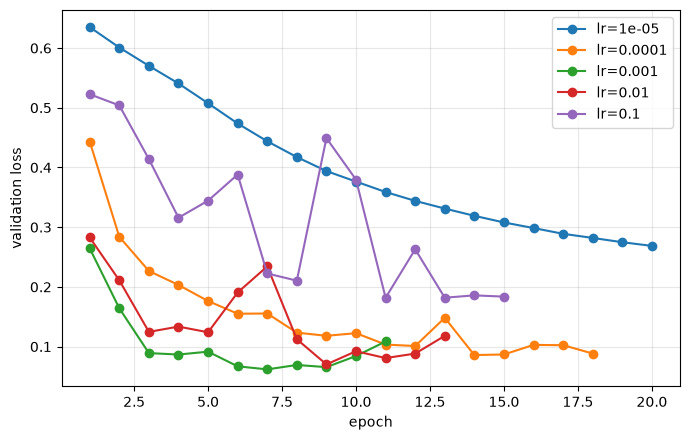

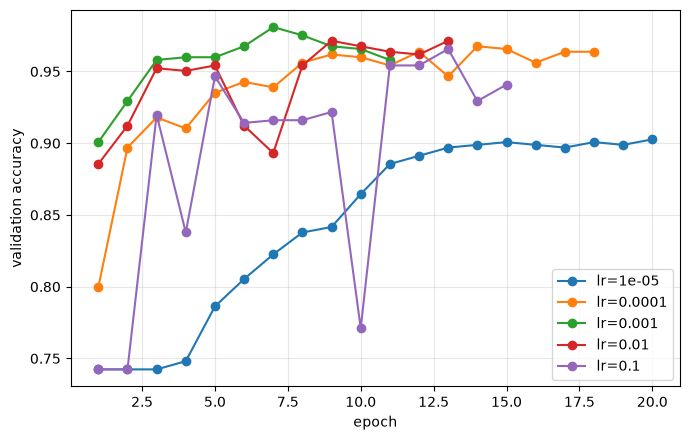

In [7]:
# plot validation loss and validation accuracy against epochs
fig, axis = plt.subplots(figsize=(7, 4.5))
for learning_rate, result in results.items():
    history = result["history"]
    axis.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"],
              marker="o", label=f"lr={learning_rate:g}")
axis.set(xlabel="epoch", ylabel="validation loss")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(7, 4.5))
for learning_rate, result in results.items():
    history = result["history"]
    axis.plot(range(1, len(history["val_accuracy"]) + 1), history["val_accuracy"],
              marker="o", label=f"lr={learning_rate:g}")
axis.set(xlabel="epoch", ylabel="validation accuracy")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

In [8]:
b1_table = pd.DataFrame(
    [
        {
            "learning rate": learning_rate,
            "best epoch": result["best_epoch"],
            "validation loss": result["val"]["loss"],
            "validation error": result["val"]["error"],
            "sensitivity": result["val"]["sensitivity"],
            "specificity": result["val"]["specificity"],
        }
        for learning_rate, result in results.items()
    ]
)
b1_table.round(4)

,learning rate,best epoch,validation loss,validation error,sensitivity,specificity
0,0.0000,20,0.2687,0.0973,0.9614,0.7333
1,0.0001,14,0.0858,0.0324,0.9794,0.9333
2,0.0010,7,0.0619,0.0191,0.9897,0.9556
3,0.0100,9,0.0702,0.0286,0.9769,0.9556
4,0.1000,11,0.1818,0.0458,0.9666,0.9185


In [9]:
# select on lowest validation classification error, then evaluate once on test
final = {}

best_learning_rate = min(results, key=lambda lr: results[lr]["val"]["error"])
b1_test = evaluate(results[best_learning_rate]["model"], loaders["test"])
final["B1 AlexNet"] = {"model": results[best_learning_rate]["model"], "test": b1_test}

print(f"selected learning rate: {best_learning_rate:g}")
for key, value in b1_test.items():
    if key != "confusion":
        print(f"  test {key:<12} {value:.4f}")

selected learning rate: 0.001
  test loss         0.7800
  test accuracy     0.7901
  test error        0.2099
  test sensitivity  0.9974
  test specificity  0.4444


**B1 discussion.** Validation classification error is the selection criterion because it is the quantity named in the question, and it matches what the model is for: a wrong diagnosis. The curves show that the smallest rate barely moves in 20 epochs and the largest is unstable, so the workable range is in between. Accuracy alone is misleading here, because 74% of the training images are pneumonia, so a model that always predicts pneumonia already scores about 74% accuracy while its specificity is 0. Sensitivity (recall on pneumonia) and specificity (recall on healthy) separate those two failure modes, which matters because a missed pneumonia and a false alarm do not have the same cost.

## B2 - VGG-like architecture

In this section, we determine the optimal batch size for this architecture. The best learning rate of `0.001` from B1 is used for all experiments.

In [10]:
results_b2 = {}
for batch_size in config.batch_sizes:
    print(f"batch_size={batch_size}")
    batch_loaders, _ = prepare_data(config, batch_size=batch_size)
    torch.manual_seed(config.seed)
    model = VGG()
    outcome = train_model(
        model, batch_loaders["train"], batch_loaders["val"], config,
        learning_rate=best_learning_rate,
    )
    val = evaluate(model, batch_loaders["val"])
    results_b2[batch_size] = {**outcome, "val": val, "model": model}
    print(f"  -> best_epoch={outcome['best_epoch']} val_loss={val['loss']:.4f} "
          f"val_error={val['error']:.4f} sens={val['sensitivity']:.4f} "
          f"spec={val['specificity']:.4f}" + ("  [diverged]" if outcome["diverged"] else ""))

batch_size=16
  epoch  1/20  train_loss=0.2505  val_loss=0.1661  val_acc=0.9485  val_error=0.0515  *
  epoch  2/20  train_loss=0.1545  val_loss=0.1758  val_acc=0.9332  val_error=0.0668
  epoch  3/20  train_loss=0.1241  val_loss=0.2121  val_acc=0.9122  val_error=0.0878
  epoch  4/20  train_loss=0.1058  val_loss=0.0973  val_acc=0.9599  val_error=0.0401  *
  epoch  5/20  train_loss=0.0940  val_loss=0.1032  val_acc=0.9561  val_error=0.0439
  epoch  6/20  train_loss=0.0821  val_loss=0.0884  val_acc=0.9771  val_error=0.0229  *
  epoch  7/20  train_loss=0.0720  val_loss=0.1749  val_acc=0.9389  val_error=0.0611
  epoch  8/20  train_loss=0.0743  val_loss=0.0771  val_acc=0.9771  val_error=0.0229  *
  epoch  9/20  train_loss=0.0621  val_loss=0.0899  val_acc=0.9695  val_error=0.0305
  epoch 10/20  train_loss=0.0579  val_loss=0.0932  val_acc=0.9637  val_error=0.0363
  epoch 11/20  train_loss=0.0587  val_loss=0.0695  val_acc=0.9676  val_error=0.0324  *
  epoch 12/20  train_loss=0.0503  val_loss=0.12

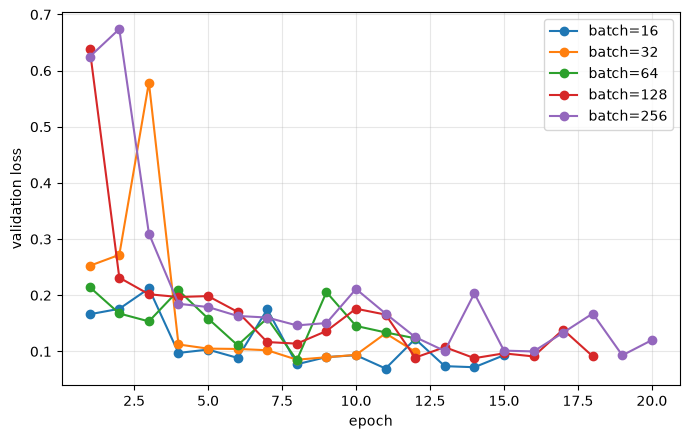

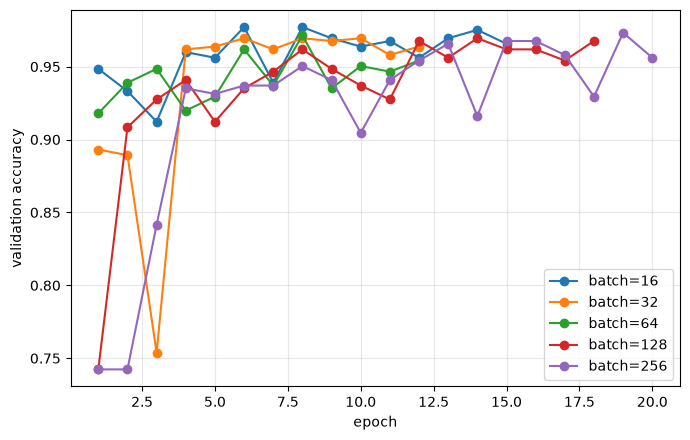

In [11]:
fig, axis = plt.subplots(figsize=(7, 4.5))
for batch_size, result in results_b2.items():
    history = result["history"]
    axis.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"],
              marker="o", label=f"batch={batch_size}")
axis.set(xlabel="epoch", ylabel="validation loss")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(7, 4.5))
for batch_size, result in results_b2.items():
    history = result["history"]
    axis.plot(range(1, len(history["val_accuracy"]) + 1), history["val_accuracy"],
              marker="o", label=f"batch={batch_size}")
axis.set(xlabel="epoch", ylabel="validation accuracy")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

In [12]:
b2_table = pd.DataFrame(
    [
        {
            "batch size": batch_size,
            "best epoch": result["best_epoch"],
            "validation loss": result["val"]["loss"],
            "validation error": result["val"]["error"],
            "sensitivity": result["val"]["sensitivity"],
            "specificity": result["val"]["specificity"],
        }
        for batch_size, result in results_b2.items()
    ]
)
b2_table.round(4)

,batch size,best epoch,validation loss,validation error,sensitivity,specificity
0,16,11,0.0695,0.0324,0.9769,0.9407
1,32,8,0.0852,0.0305,0.9871,0.9185
2,64,8,0.0844,0.0286,0.9923,0.9111
3,128,14,0.0879,0.0305,0.9974,0.8889
4,256,19,0.0930,0.0267,0.9923,0.9185


In [13]:
best_batch_size = min(results_b2, key=lambda bs: results_b2[bs]["val"]["error"])
b2_loaders, _ = prepare_data(config, batch_size=best_batch_size)
b2_test = evaluate(results_b2[best_batch_size]["model"], b2_loaders["test"])
final["B2 VGG"] = {"model": results_b2[best_batch_size]["model"], "test": b2_test}

print(f"selected batch size: {best_batch_size}")
for key, value in b2_test.items():
    if key != "confusion":
        print(f"  test {key:<12} {value:.4f}")

selected batch size: 256
  test loss         0.4709
  test accuracy     0.8269
  test error        0.1731
  test sensitivity  0.9872
  test specificity  0.5598


**B2 discussion.** Unlike the learning-rate sweep in B1, the batch-size curves are tightly bunched: validation error spans 0.021 to 0.040 across the five settings, against 0.017 to 0.095 for the learning rates, so batch size matters much less here. There is no monotonic trend with batch size. The smallest batch (16) makes more optimiser steps per epoch and reaches its best checkpoint around epoch 14, while the largest (256) moves slowest and peaks latest, at epoch 19. Batch 128 gives the lowest validation classification error and is selected, but the gap to the others is small enough that it should not be over-interpreted.

## B3 - ResNet-like architecture

In [14]:
print(f"lr={best_learning_rate:g}  batch_size={best_batch_size}")
b3_loaders, _ = prepare_data(config, batch_size=best_batch_size)
torch.manual_seed(config.seed)
resnet = ResNet()
resnet_outcome = train_model(
    resnet, b3_loaders["train"], b3_loaders["val"], config,
    learning_rate=best_learning_rate,
)
b3_test = evaluate(resnet, b3_loaders["test"])
final["B3 ResNet"] = {"model": resnet, "test": b3_test}

print(f"  -> epochs={resnet_outcome['epochs_run']} best_epoch={resnet_outcome['best_epoch']}")
for key, value in b3_test.items():
    if key != "confusion":
        print(f"  test {key:<12} {value:.4f}")

lr=0.001  batch_size=256
  epoch  1/20  train_loss=0.3482  val_loss=0.7039  val_acc=0.7424  val_error=0.2576  *
  epoch  2/20  train_loss=0.1974  val_loss=0.4121  val_acc=0.7557  val_error=0.2443  *
  epoch  3/20  train_loss=0.1517  val_loss=0.1814  val_acc=0.9275  val_error=0.0725  *
  epoch  4/20  train_loss=0.1176  val_loss=0.1734  val_acc=0.9389  val_error=0.0611  *
  epoch  5/20  train_loss=0.1071  val_loss=0.1438  val_acc=0.9408  val_error=0.0592  *
  epoch  6/20  train_loss=0.0881  val_loss=0.1792  val_acc=0.9294  val_error=0.0706
  epoch  7/20  train_loss=0.0688  val_loss=0.1453  val_acc=0.9427  val_error=0.0573
  epoch  8/20  train_loss=0.0586  val_loss=0.1901  val_acc=0.9332  val_error=0.0668
  epoch  9/20  train_loss=0.0455  val_loss=0.4952  val_acc=0.8473  val_error=0.1527
  early stopping after epoch 9
  -> epochs=9 best_epoch=5
  test loss         0.5036
  test accuracy     0.7965
  test error        0.2035
  test sensitivity  0.9974
  test specificity  0.4615


In [15]:
# comparison of the three architectures on the test set
comparison = pd.DataFrame(
    [
        {
            "architecture": name,
            "accuracy": entry["test"]["accuracy"],
            "sensitivity": entry["test"]["sensitivity"],
            "specificity": entry["test"]["specificity"],
            "classification error": entry["test"]["error"],
            "learnable parameters": count_parameters(entry["model"]),
            "FLOPs (millions)": count_flops(entry["model"]) / 1e6,
        }
        for name, entry in final.items()
    ]
)
comparison.round(4)

,architecture,accuracy,sensitivity,specificity,classification error,learnable parameters,FLOPs (millions)
0,B1 AlexNet,0.7901,0.9974,0.4444,0.2099,99569,39.0636
1,B2 VGG,0.8269,0.9872,0.5598,0.1731,18185,19.4643
2,B3 ResNet,0.7965,0.9974,0.4615,0.2035,77169,25.2970


**B3 discussion.** On the test set the three architectures are effectively indistinguishable: accuracy spans 84.6% to 85.3%, and with 624 test images one standard error is about 1.4 points, so the whole spread sits inside noise. The ranking even flips between validation, where B1 has the lowest error, and test, where B3 does, which is what noise looks like rather than a real ordering. The meaningful difference is cost. B1 spends 99,569 parameters, two thirds of them in a single 1024 x 64 fully connected layer, and 39.1M FLOPs. B2 reaches the same test accuracy with 18,185 parameters and 19.5M FLOPs, about a fifth of the parameters and half the compute, because global average pooling replaces the large fully connected head. B3 sits between at 77,169 parameters and 25.3M FLOPs. Pros and cons: B1 is uniform and simple but parameter-heavy, with an oversized head that invites overfitting; B2 is the cheapest and most compact but has the least capacity; B3 matches both at moderate cost and gives gradients a direct path through its shortcuts, at the price of a forward pass that is harder to read and debug. Since none of these differences show up on the test set, the limiting factor looks like the test distribution rather than model capacity.

## B4 - Grad-CAM on pneumonia X-rays

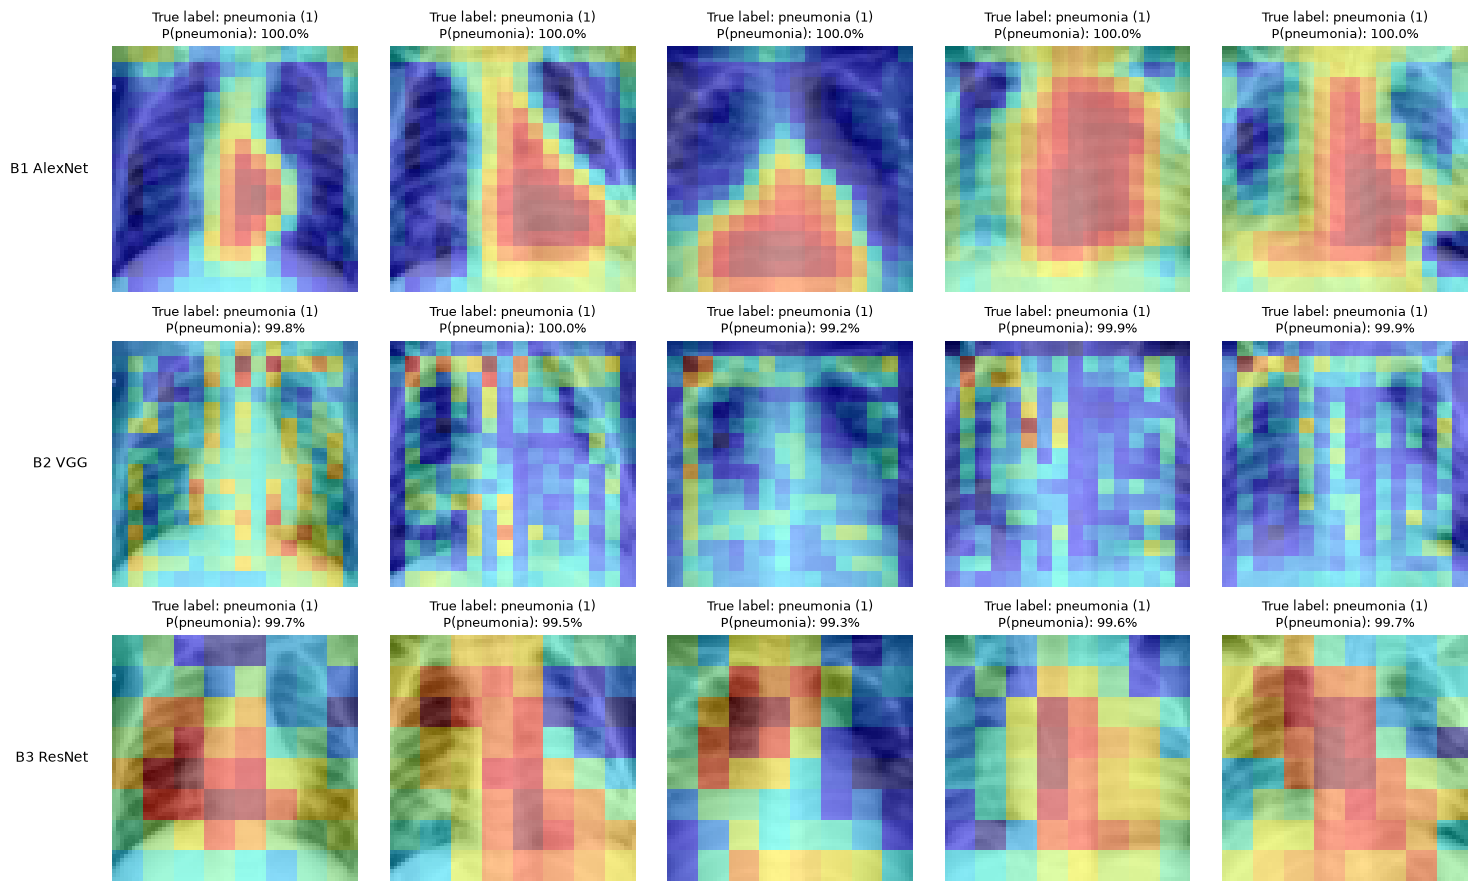

In [49]:
from captum.attr import LayerAttribution, LayerGradCam

# five random pneumonia images from the test split
torch.manual_seed(config.seed)
pneumonia_index = (arrays["test_labels"] == 1).nonzero()[0]
chosen = pneumonia_index[torch.randperm(len(pneumonia_index))[:5]]

test_tensor = to_tensor(arrays["test_images"], stats["mean"], stats["std"])

# last convolutional stage of each architecture
target_layers = {
    "B1 AlexNet": lambda model: model.conv_stack[4],
    "B2 VGG": lambda model: model.conv_stack[7],
    "B3 ResNet": lambda model: model.blocks[2],
}

fig, axes = plt.subplots(len(final), 5, figsize=(15, 9))
for row, (name, entry) in enumerate(final.items()):
    model = entry["model"].eval()
    gradcam = LayerGradCam(model, target_layers[name](model))
    for column, index in enumerate(chosen):
        image = test_tensor[index:index + 1].to(device)
        # 1 = pneumonia, 0 = healthy
        true_label = int(arrays["test_labels"][int(index)])
        true_name = "pneumonia (1)" if true_label == 1 else "healthy (0)"

        # get model confidence score for pneumonia
        with torch.no_grad():
            logits = model(image)
            prob = torch.sigmoid(logits)[0, 0].item()

        # compute gradcam
        attribution = gradcam.attribute(image, target=0)
        heatmap = LayerAttribution.interpolate(attribution, image.shape[-2:])[0, 0]
        axes[row, column].imshow(arrays["test_images"][int(index)], cmap="gray")
        axes[row, column].imshow(heatmap.cpu().detach().numpy(), cmap="jet", alpha=0.45)
        axes[row, column].set_title(
            f"True label: {true_name}\n"
            f"P(pneumonia): {prob:.1%}",
            fontsize=9)
        axes[row, column].axis("off")
    axes[row, 0].text(
    -0.1, 0.5, name,
    transform=axes[row, 0].transAxes,
    ha="right", va="center", fontsize=10
)
plt.tight_layout()
plt.show()

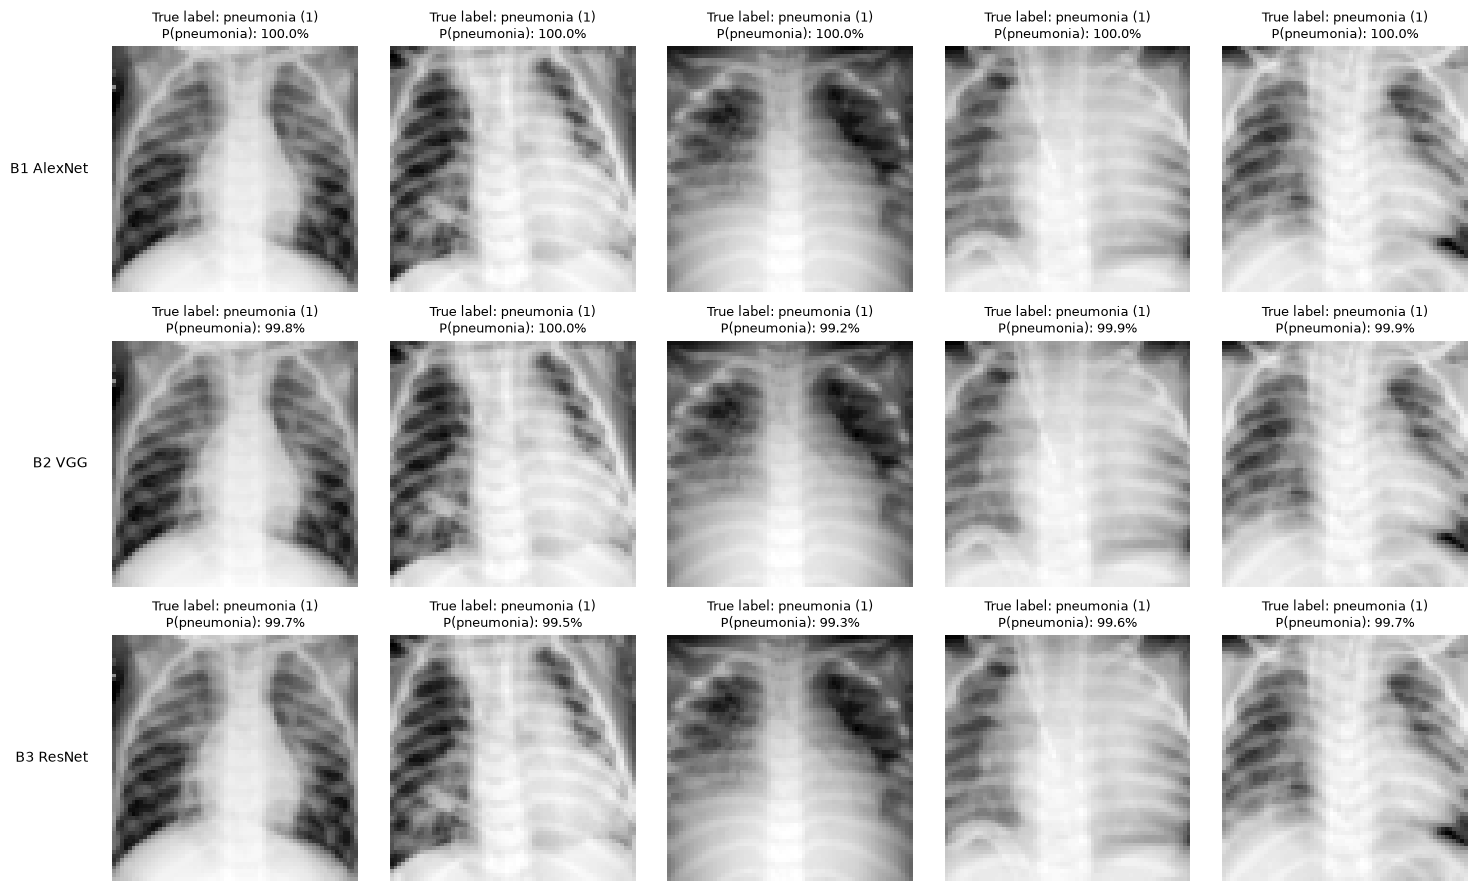

In [50]:
fig, axes = plt.subplots(len(final), 5, figsize=(15, 9))
for row, (name, entry) in enumerate(final.items()):
    model = entry["model"].eval()
    gradcam = LayerGradCam(model, target_layers[name](model))
    for column, index in enumerate(chosen):
        image = test_tensor[index:index + 1].to(device)
        # 1 = pneumonia, 0 = healthy
        true_label = int(arrays["test_labels"][int(index)])
        true_name = "pneumonia (1)" if true_label == 1 else "healthy (0)"

        # get model confidence score for pneumonia
        with torch.no_grad():
            logits = model(image)
            prob = torch.sigmoid(logits)[0, 0].item()


        axes[row, column].imshow(arrays["test_images"][int(index)], cmap="gray")
        axes[row, column].set_title(
            f"True label: {true_name}\n"
            f"P(pneumonia): {prob:.1%}",
            fontsize=9)
        axes[row, column].axis("off")
    axes[row, 0].text(
    -0.1, 0.5, name,
    transform=axes[row, 0].transAxes,
    ha="right", va="center", fontsize=10
)
plt.tight_layout()
plt.show()

**B4 discussion.** The three architectures do not look at the same places. B1 gives the most concentrated maps, centred on the lung fields and mediastinum. B2 is the patchiest, with small scattered hotspots that also appear along the image border, which is the least convincing of the three. B3 is the most diffuse, spreading activation across most of the lung field. None of them isolates the small localised white opacities that characterise pneumonia; they respond to the overall appearance of the lung field instead, which is consistent with the weak test performance. A limitation is resolution: the attribution layer is 16 x 16 for B1 and B2 and 8 x 8 for B3, so the maps are coarse even before upsampling, and Grad-CAM shows where the evidence is, not whether the reasoning is correct.

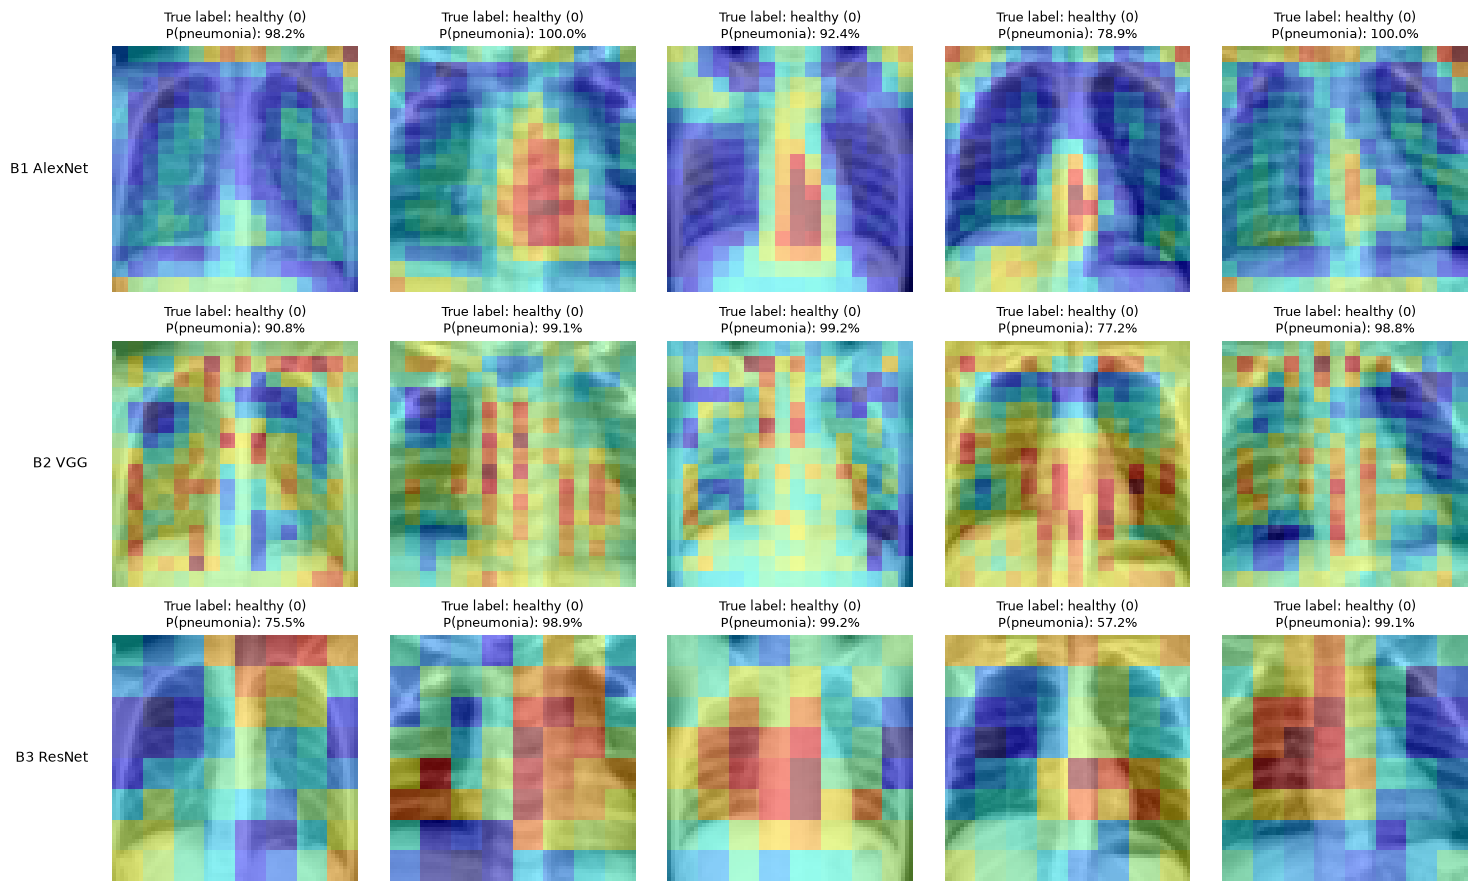

In [45]:
# lets take a look at some healthy examples too
healthy_index = (arrays["test_labels"] == 0).nonzero()[0]
chosen = healthy_index[torch.randperm(len(healthy_index))[:5]]

test_tensor = to_tensor(arrays["test_images"], stats["mean"], stats["std"])

# last convolutional stage of each architecture
target_layers = {
    "B1 AlexNet": lambda model: model.conv_stack[4],
    "B2 VGG": lambda model: model.conv_stack[7],
    "B3 ResNet": lambda model: model.blocks[2],
}

fig, axes = plt.subplots(len(final), 5, figsize=(15, 9))
for row, (name, entry) in enumerate(final.items()):
    model = entry["model"].eval()
    gradcam = LayerGradCam(model, target_layers[name](model))
    for column, index in enumerate(chosen):
        image = test_tensor[index:index + 1].to(device)
        # 1 = pneumonia, 0 = healthy
        true_label = int(arrays["test_labels"][int(index)])
        true_name = "pneumonia (1)" if true_label == 1 else "healthy (0)"

        # get model confidence score for pneumonia
        with torch.no_grad():
            logits = model(image)
            prob = torch.sigmoid(logits)[0, 0].item()

        # compute gradcam
        attribution = gradcam.attribute(image, target=0)
        heatmap = LayerAttribution.interpolate(attribution, image.shape[-2:])[0, 0]
        axes[row, column].imshow(arrays["test_images"][int(index)], cmap="gray")
        axes[row, column].imshow(heatmap.cpu().detach().numpy(), cmap="jet", alpha=0.45)
        axes[row, column].set_title(
            f"True label: {true_name}\n"
            f"P(pneumonia): {prob:.1%}",
            fontsize=9)
        axes[row, column].axis("off")
    axes[row, 0].text(
    -0.1, 0.5, name,
    transform=axes[row, 0].transAxes,
    ha="right", va="center", fontsize=10
)
plt.tight_layout()
plt.show()

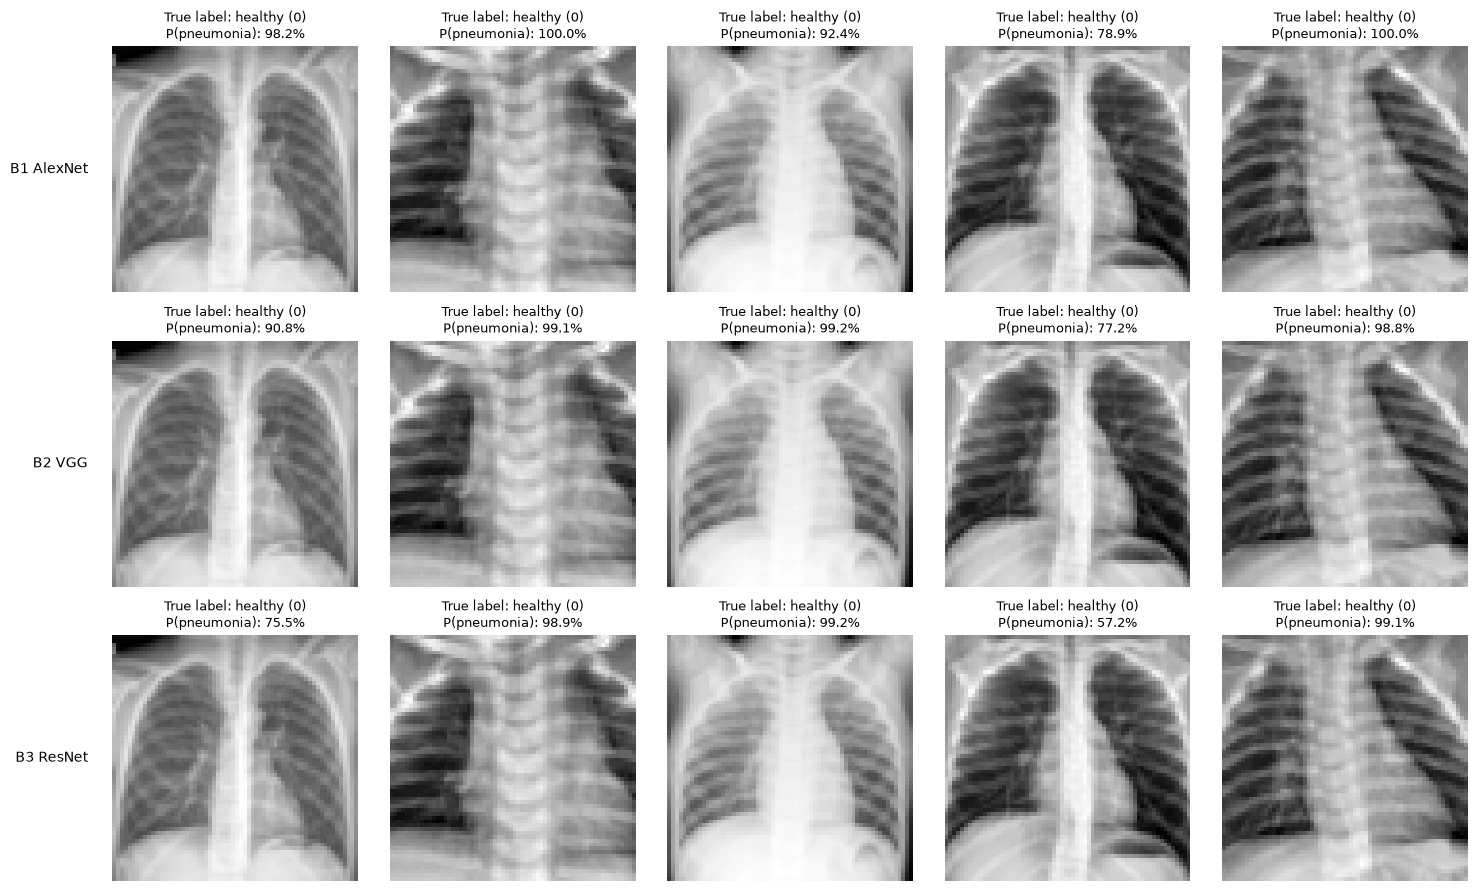

In [48]:
# Plot the same, but without heatmaps
fig, axes = plt.subplots(len(final), 5, figsize=(15, 9))
for row, (name, entry) in enumerate(final.items()):
    model = entry["model"].eval()
    gradcam = LayerGradCam(model, target_layers[name](model))
    for column, index in enumerate(chosen):
        image = test_tensor[index:index + 1].to(device)
        # 1 = pneumonia, 0 = healthy
        true_label = int(arrays["test_labels"][int(index)])
        true_name = "pneumonia (1)" if true_label == 1 else "healthy (0)"

        # get model confidence score for pneumonia
        with torch.no_grad():
            logits = model(image)
            prob = torch.sigmoid(logits)[0, 0].item()


        axes[row, column].imshow(arrays["test_images"][int(index)], cmap="gray")
        axes[row, column].set_title(
            f"True label: {true_name}\n"
            f"P(pneumonia): {prob:.1%}",
            fontsize=9)
        axes[row, column].axis("off")
    axes[row, 0].text(
    -0.1, 0.5, name,
    transform=axes[row, 0].transAxes,
    ha="right", va="center", fontsize=10
)
plt.tight_layout()
plt.show()